# COU 07506 — Week 3: Lab 1B, Convolution, Correlation and Difference Equations

**Student:** Zaid Yaseer Yussuf &nbsp;|&nbsp; **Registration number:** 240242479517 &nbsp;|&nbsp;
**Class:** BEng24COE &nbsp;|&nbsp; **Date:** 26 November 2026 &nbsp;|&nbsp;
**Submission:** Individual laboratory work.

## Pre-lab preparation

**Reading.** Handout §1.7–§1.9.

**(a)** Convolution of x = {1, −1, 2} with h = {2, 1, 0, 1}:

y(0) = 1·2 = 2, y(1) = 1·1 + (−1)·2 = −1, y(2) = 1·0 + (−1)·1 + 2·2 = 3,
y(3) = 1·1 + (−1)·0 + 2·1 = 3, y(4) = (−1)·1 + 2·0 = −1, y(5) = 2·1 = 2.
The result is **{2, −1, 3, 3, −1, 2}**, verified by the code below.

**(b)** For y(n) = n·x(n), delaying the input gives n·x(n − n₀), while delaying
the output gives (n − n₀)·x(n − n₀). They are different for n₀ ≠ 0, so the
system is **not time-invariant**.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (9, 3.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
FIGDIR = ROOT / "report" / "figures"
FIGDIR.mkdir(parents=True, exist_ok=True)
DATA = ROOT / "data"
REPORT = ROOT / "report"
REPORT.mkdir(parents=True, exist_ok=True)
print("Repository root:", ROOT)

Repository root: C:\Users\zayee\Documents\Default Project\COU07506-labs


In [2]:
import time

def conv(x, h):
    """Linear convolution directly from y(n) = sum_k x(k) h(n-k)."""
    x = np.asarray(x, dtype=float)
    h = np.asarray(h, dtype=float)
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]
    return y

def delay_estimate(sigma, seed=1, true_delay=37, N=500):
    rng = np.random.default_rng(seed)
    x = rng.standard_normal(N)
    y = np.concatenate([np.zeros(true_delay), 0.6 * x])[:N] + sigma * rng.standard_normal(N)
    r = signal.correlate(y, x, mode="full")
    lags = signal.correlation_lags(len(y), len(x), mode="full")
    return int(lags[np.argmax(r)]), lags, r

def delay_success_rate(sigma, trials=300, true_delay=37):
    ok = sum(delay_estimate(sigma, seed=1000 + s, true_delay=true_delay)[0] == true_delay
             for s in range(trials))
    return ok / trials

## Task 3.1 — Convolution from the definition

Compare the direct double loop with `np.convolve` for short sequences, then time
both on two random sequences of length 2000.

In [3]:
y_manual = conv([1, 2, 3, 1], [1, 1, 1])
y_np = np.convolve([1, 2, 3, 1], [1, 1, 1])
print("conv([1,2,3,1],[1,1,1]) :", y_manual.astype(int).tolist())
print("np.convolve            :", y_np.astype(int).tolist())

x_pre, h_pre = [1, -1, 2], [2, 1, 0, 1]
y_pre = conv(x_pre, h_pre)
y_pre_np = np.convolve(x_pre, h_pre)
print("pre-lab conv           :", y_pre.astype(int).tolist())
print("pre-lab np.convolve    :", y_pre_np.astype(int).tolist())

rng = np.random.default_rng(0)
a_rand, b_rand = rng.standard_normal(2000), rng.standard_normal(2000)
t0 = time.perf_counter(); y_loop = conv(a_rand, b_rand); t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); y_fast = np.convolve(a_rand, b_rand); t_fast = time.perf_counter() - t0
print(f"double loop : {t_loop:.4f} s")
print(f"np.convolve : {t_fast*1000:.3f} ms")
print(f"speed ratio : {t_loop/t_fast:.0f}x ; results agree:", np.allclose(y_loop, y_fast))

conv([1,2,3,1],[1,1,1]) : [1, 3, 6, 6, 4, 1]
np.convolve            : [1, 3, 6, 6, 4, 1]
pre-lab conv           : [2, -1, 3, 3, -1, 2]
pre-lab np.convolve    : [2, -1, 3, 3, -1, 2]


double loop : 10.2548 s
np.convolve : 3.124 ms
speed ratio : 3283x ; results agree: True


## Task 3.2 — Smoothing a noisy signal

x(n) = sin(2πn/50) + 0.5w(n), 0 ≤ n < 300, is convolved with moving-average
filters of length M = 3, 9 and 25 using `mode="same"`. The RMS error is computed
away from the ends to avoid edge effects.

,M,gain_at_50_samples,rms_error
0,0,1.000,0.509
1,3,0.995,0.304
2,9,0.948,0.187
3,25,0.637,0.271


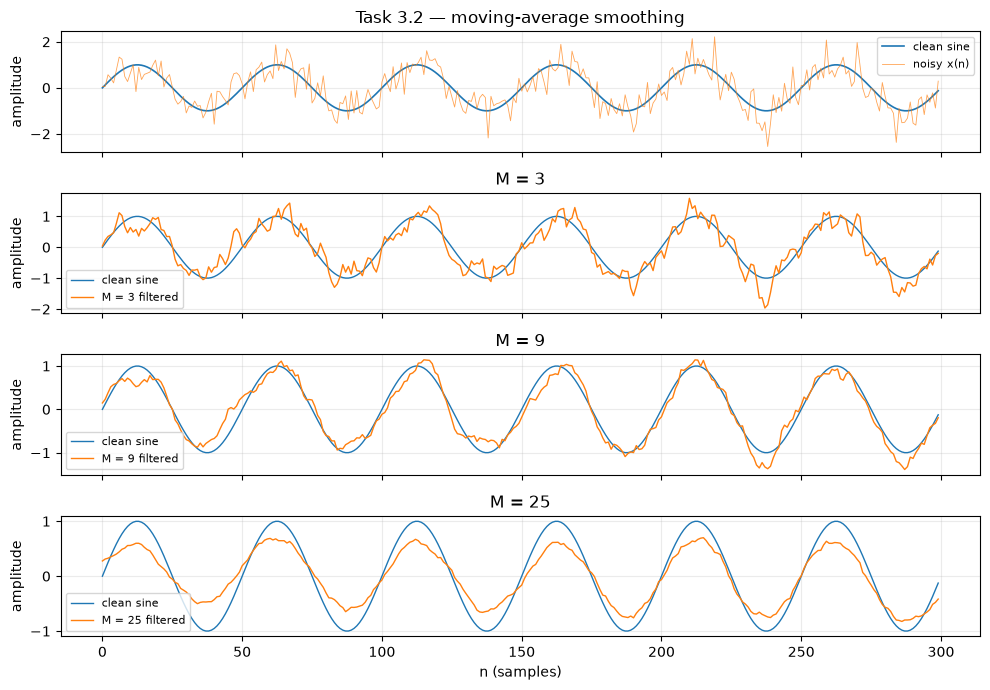

In [4]:
rng = np.random.default_rng(0)
n_s = np.arange(300)
clean = np.sin(2 * np.pi * n_s / 50)
x_noisy = clean + 0.5 * rng.standard_normal(300)
smooth_rows = []
smoothed = {}
for M in [3, 9, 25]:
    y = np.convolve(x_noisy, np.ones(M) / M, mode="same")
    core = slice(M, 300 - M)
    w0 = 2 * np.pi / 50
    gain = abs(np.sin(M * w0 / 2) / (M * np.sin(w0 / 2)))
    rms_err = float(np.sqrt(np.mean((y[core] - clean[core]) ** 2)))
    smooth_rows.append({"M": M, "gain_at_50_samples": round(float(gain), 3),
                        "rms_error": round(rms_err, 3)})
    smoothed[M] = y
smooth_rows.insert(0, {"M": 0, "gain_at_50_samples": 1.0,
                       "rms_error": round(float(np.sqrt(np.mean((x_noisy-clean)**2))), 3)})
display(pd.DataFrame(smooth_rows))

fig, axes = plt.subplots(4, 1, figsize=(10, 7), sharex=True)
axes[0].plot(n_s, clean, label="clean sine", lw=1.2)
axes[0].plot(n_s, x_noisy, label="noisy x(n)", lw=0.6, alpha=0.7)
axes[0].set_title("Task 3.2 — moving-average smoothing")
for ax, M in zip(axes[1:], [3, 9, 25]):
    ax.plot(n_s, clean, label="clean sine", lw=1.0)
    ax.plot(n_s, smoothed[M], label=f"M = {M} filtered", lw=1.0)
    ax.set_title(f"M = {M}")
for ax in axes:
    ax.set_ylabel("amplitude")
    ax.legend(fontsize=8)
axes[-1].set_xlabel("n (samples)")
fig.tight_layout()
fig.savefig(FIGDIR / "week03_task3_2.png", dpi=160, bbox_inches="tight")
plt.show()

M = 9 gives the smallest error; M = 25 removes more noise but attenuates the
wanted sine, so the total error rises again.

## Task 3.3 — Testing linearity and time-invariance

Three systems are tested with random inputs, a = 2, b = −3 and a 5-sample delay.

In [5]:
rng = np.random.default_rng(0)
x1, x2 = rng.standard_normal(50), rng.standard_normal(50)
a_coef, b_coef = 2.0, -3.0
systems = {"x^2": lambda x: x**2,
           "n x(n)": lambda x: np.arange(len(x)) * x,
           "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]}
system_rows = []
for name, T in systems.items():
    linear = bool(np.allclose(T(a_coef*x1 + b_coef*x2), a_coef*T(x1) + b_coef*T(x2)))
    xd = np.concatenate([np.zeros(5), x1])[:50]
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]
    tinv = bool(np.allclose(T(xd), yd))
    system_rows.append({"system": name, "linear": linear,
                        "time_invariant": tinv, "LTI": linear and tinv})
    print(f"{name:15s} linear={linear}  time-invariant={tinv}")
display(pd.DataFrame(system_rows))

x^2             linear=False  time-invariant=True
n x(n)          linear=True  time-invariant=False
moving average  linear=True  time-invariant=True


,system,linear,time_invariant,LTI
0,x^2,False,True,False
1,n x(n),True,False,False
2,moving average,True,True,True


The squarer is time-invariant but non-linear (the cross term 2abx₁x₂ breaks
superposition). Multiplication by n is linear but time-varying; the moving
average has constant coefficients and is LTI.

## Task 3.4 — Finding a hidden delay

A noise-free 500-sample sequence is delayed by 37 samples, scaled by 0.6 and
corrupted with Gaussian noise. The cross-correlation peak gives the delay.

estimated delay at sigma=0.5: 37 samples
distance at 343 m/s and fs=1000 Hz: 12.69 m


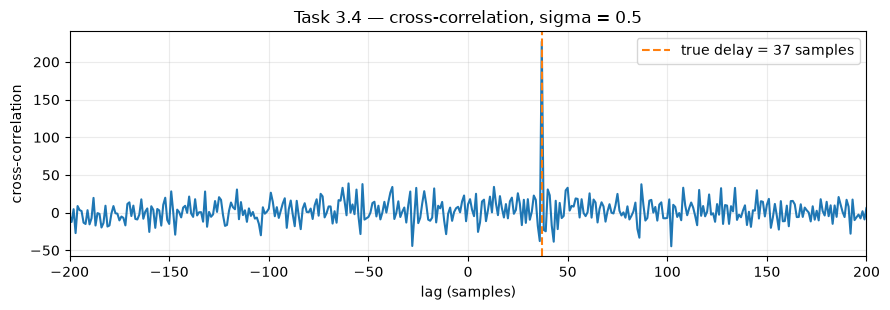

sigma= 0.5: estimate= 37, success=100%
sigma=   1: estimate= 37, success=100%


sigma=   2: estimate= 37, success=100%
sigma=   4: estimate= 87, success=68%


sigma=   8: estimate= 87, success=15%
sigma=  16: estimate= 87, success=3%


,sigma,single_run_estimate,success_rate_300_trials
0,0.5,37,1.000
1,1.0,37,1.000
2,2.0,37,1.000
3,4.0,87,0.683
4,8.0,87,0.150
5,16.0,87,0.030


In [6]:
est05, lags05, r05 = delay_estimate(0.5, seed=1)
print("estimated delay at sigma=0.5:", est05, "samples")
print(f"distance at 343 m/s and fs=1000 Hz: {est05/1000*343:.2f} m")

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(lags05, r05)
ax.axvline(37, color="C1", ls="--", label="true delay = 37 samples")
ax.set_xlim(-200, 200)
ax.set_title("Task 3.4 — cross-correlation, sigma = 0.5")
ax.set_xlabel("lag (samples)")
ax.set_ylabel("cross-correlation")
ax.legend()
fig.tight_layout()
fig.savefig(FIGDIR / "week03_task3_4.png", dpi=160, bbox_inches="tight")
plt.show()

delay_rows = []
for sigma in [0.5, 1, 2, 4, 8, 16]:
    est, _, _ = delay_estimate(sigma, seed=1)
    rate = delay_success_rate(sigma, trials=300)
    delay_rows.append({"sigma": sigma, "single_run_estimate": est,
                       "success_rate_300_trials": round(rate, 3)})
    print(f"sigma={sigma:4g}: estimate={est:3d}, success={rate:.0%}")
display(pd.DataFrame(delay_rows))

## Task 3.5 — Difference equation

For y(n) − 0.75y(n−1) + 0.125y(n−2) = x(n) + x(n−1), compute h(n) by recursion,
with `lfilter` and from h(n) = 6(0.5)ⁿ − 5(0.25)ⁿ; then compute the step response.

recursion : [1.0, 1.75, 1.1875, 0.6719, 0.3555, 0.1826, 0.0925, 0.0466, 0.0234, 0.0117]
lfilter   : [1.0, 1.75, 1.1875, 0.6719, 0.3555, 0.1826, 0.0925, 0.0466, 0.0234, 0.0117]
closed form: [1.0, 1.75, 1.1875, 0.6719, 0.3555, 0.1826, 0.0925, 0.0466, 0.0234, 0.0117]
all agree : True
step final value: 5.3333  H(1) = 5.3333


,n,recursion,lfilter,closed_form
0,0,1.0000,1.0000,1.0000
1,1,1.7500,1.7500,1.7500
2,2,1.1875,1.1875,1.1875
3,3,0.6719,0.6719,0.6719
4,4,0.3555,0.3555,0.3555
5,5,0.1826,0.1826,0.1826
6,6,0.0925,0.0925,0.0925
7,7,0.0466,0.0466,0.0466
8,8,0.0234,0.0234,0.0234
9,9,0.0117,0.0117,0.0117


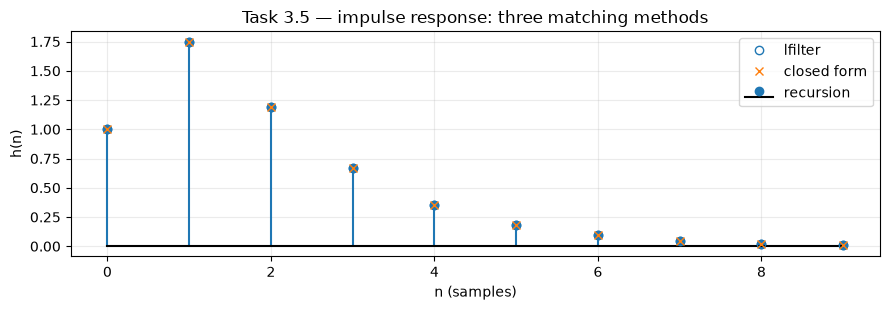

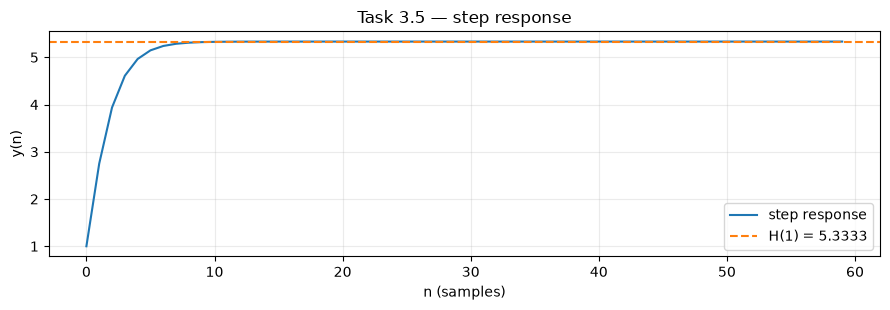

In [7]:
b_de, a_de = [1, 1], [1, -0.75, 0.125]
N_de = 10
imp = np.zeros(N_de); imp[0] = 1
h_rec = np.zeros(N_de)
for n in range(N_de):
    h_rec[n] = imp[n] + (imp[n-1] if n >= 1 else 0)
    h_rec[n] += 0.75 * (h_rec[n-1] if n >= 1 else 0) - 0.125 * (h_rec[n-2] if n >= 2 else 0)
h_lf = signal.lfilter(b_de, a_de, imp)
n_de = np.arange(N_de)
h_cf = 6 * 0.5**n_de - 5 * 0.25**n_de
step_resp = signal.lfilter(b_de, a_de, np.ones(60))
H1 = float(sum(b_de) / sum(a_de))
print("recursion :", np.round(h_rec, 4).tolist())
print("lfilter   :", np.round(h_lf, 4).tolist())
print("closed form:", np.round(h_cf, 4).tolist())
print("all agree :", np.allclose(h_rec, h_lf) and np.allclose(h_rec, h_cf))
print("step final value:", round(float(step_resp[-1]), 4), " H(1) =", round(H1, 4))
display(pd.DataFrame({"n": n_de.tolist(), "recursion": np.round(h_rec, 4).tolist(),
                      "lfilter": np.round(h_lf, 4).tolist(),
                      "closed_form": np.round(h_cf, 4).tolist()}))

fig1, ax1 = plt.subplots(figsize=(9, 3.2))
ax1.stem(n_de, h_rec, basefmt="k-", label="recursion")
ax1.plot(n_de, h_lf, "o", mfc="none", label="lfilter")
ax1.plot(n_de, h_cf, "x", label="closed form")
ax1.set_title("Task 3.5 — impulse response: three matching methods")
ax1.set_xlabel("n (samples)")
ax1.set_ylabel("h(n)")
ax1.legend()
fig1.tight_layout()
fig1.savefig(FIGDIR / "week03_task3_5_imp.png", dpi=160, bbox_inches="tight")
plt.show()

fig2, ax2 = plt.subplots(figsize=(9, 3.2))
ax2.plot(np.arange(60), step_resp, label="step response")
ax2.axhline(H1, color="C1", ls="--", label=f"H(1) = {H1:.4f}")
ax2.set_title("Task 3.5 — step response")
ax2.set_xlabel("n (samples)")
ax2.set_ylabel("y(n)")
ax2.legend()
fig2.tight_layout()
fig2.savefig(FIGDIR / "week03_task3_5_step.png", dpi=160, bbox_inches="tight")
plt.show()

## Analysis questions

1. Both methods perform L·M multiplications (4 000 000 here). `np.convolve` is
   faster because the loops run in compiled code over whole arrays, while the
   Python double loop interprets every iteration.
2. Only the moving average is LTI, as predicted: the squarer is non-linear and
   multiplication by n is time-varying.
3. Tanzania applications: (i) cross-correlating two sensor signals on a water
   pipe to locate a leak from the time delay; (ii) radar/GPS, where correlating
   the received signal with the transmitted code gives range.
4. The system is IIR because h(n) never becomes exactly zero. It is stable: the
   poles are at z = 0.5 and 0.25 and Σ|h(n)| = H(1) = 5.333 is finite.

In [8]:
results_week03 = {
    "week": 3,
    "convolution": {"expected": [1, 3, 6, 6, 4, 1],
                    "prelab": [int(v) for v in y_pre],
                    "loop_time_s": round(float(t_loop), 4),
                    "numpy_time_s": round(float(t_fast), 6),
                    "speed_ratio": round(float(t_loop / t_fast), 1)},
    "smoothing": smooth_rows,
    "systems": system_rows,
    "delay": delay_rows,
    "diffeq": {"h": [round(float(v), 4) for v in h_rec],
               "step_final": round(float(step_resp[-1]), 4),
               "H1": round(H1, 4),
               "methods_agree": bool(np.allclose(h_rec, h_lf) and np.allclose(h_rec, h_cf))},
}
(REPORT / "results_week03.json").write_text(json.dumps(results_week03, indent=2))
print(json.dumps(results_week03, indent=2))

{
  "week": 3,
  "convolution": {
    "expected": [
      1,
      3,
      6,
      6,
      4,
      1
    ],
    "prelab": [
      2,
      -1,
      3,
      3,
      -1,
      2
    ],
    "loop_time_s": 10.2548,
    "numpy_time_s": 0.003124,
    "speed_ratio": 3282.7
  },
  "smoothing": [
    {
      "M": 0,
      "gain_at_50_samples": 1.0,
      "rms_error": 0.509
    },
    {
      "M": 3,
      "gain_at_50_samples": 0.995,
      "rms_error": 0.304
    },
    {
      "M": 9,
      "gain_at_50_samples": 0.948,
      "rms_error": 0.187
    },
    {
      "M": 25,
      "gain_at_50_samples": 0.637,
      "rms_error": 0.271
    }
  ],
  "systems": [
    {
      "system": "x^2",
      "linear": false,
      "time_invariant": true,
      "LTI": false
    },
    {
      "system": "n x(n)",
      "linear": true,
      "time_invariant": false,
      "LTI": false
    },
    {
      "system": "moving average",
      "linear": true,
      "time_invariant": true,
      "LTI": true
    }
  ]

## AI-use statement

**Tool:** OpenCode (model Big Pickle). **Used for:** drafting the Python code and
written answers in this notebook. **Verification:** the notebook was restarted and
run from top to bottom; `conv` was checked against `np.convolve` and the expected
{1, 3, 6, 6, 4, 1}; system properties were checked against the definitions; the
delay estimate was checked against the known 37 samples; and the three impulse
responses were compared with `np.allclose`. I can explain every line of code.